In [1]:
import seaborn as sns
from sklearn.datasets import make_blobs

In [2]:
X, y = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    random_state=42
)

<Axes: >

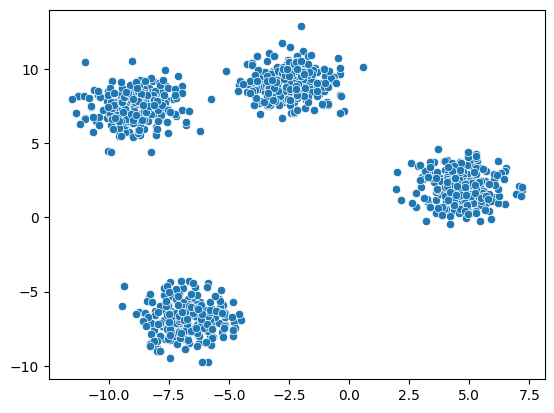

In [3]:
sns.scatterplot(x=X[:, 0], y=X[:,1])

<Axes: >

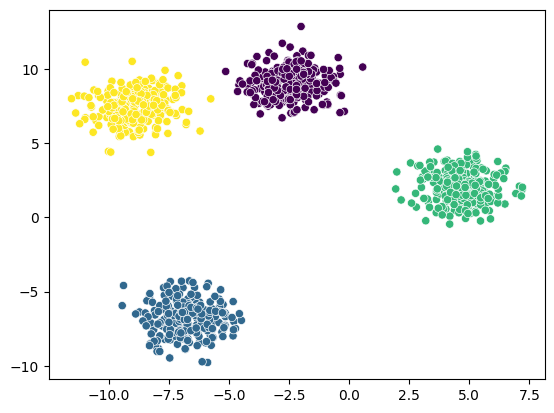

In [4]:
from sklearn.cluster import KMeans

k = 4
kmeans = KMeans(
    n_clusters=k,
    random_state=42
)

labels = kmeans.fit_predict(X)

sns.scatterplot(x=X[:, 0], y=X[:,1],c=labels)

In [5]:
wcss = []
for k in range(1, 21):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(X)
    wcss.append(kmeans.inertia_)

<Axes: >

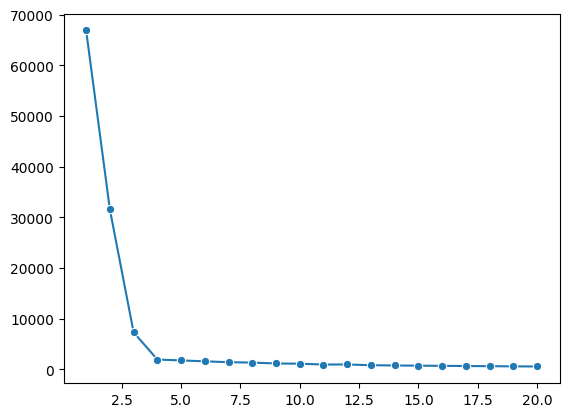

In [6]:
sns.lineplot(x=range(1, 21), y=wcss, marker="o")

In [7]:

!pip install kneed

In [8]:
from kneed import KneeLocator

# knee = KneeLocator(range(1, len(wcss) + 1), wcss, curve="convex", direction="decreasing")
knee = KneeLocator(range(1, len(wcss) + 1), wcss, curve="convex", direction="decreasing")
knee.elbow

np.int64(4)

In [9]:
from sklearn.metrics import silhouette_score

ss = []

for  k in range(2, 21):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)

    ss.append(score)

<Axes: >

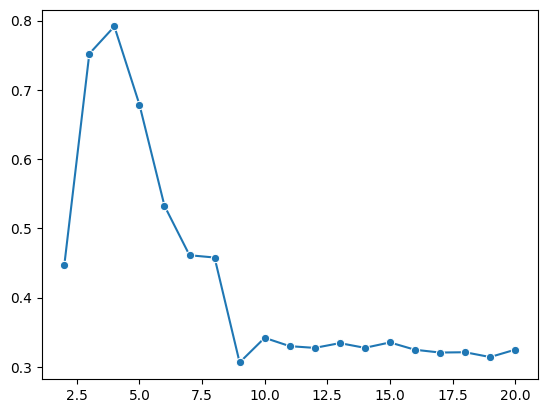

In [10]:
sns.lineplot(x=range(2, 21), y=ss, marker="o")

# Iris Dataset

In [11]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris(as_frame=True).frame
X = iris.drop(columns=["target"])
y = iris["target"]
X.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<Axes: xlabel='sepal length (cm)', ylabel='petal width (cm)'>

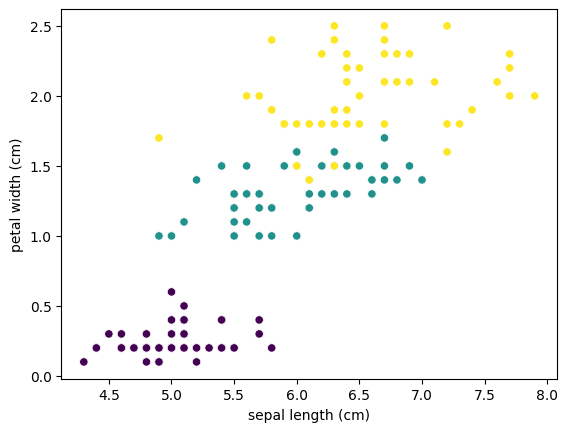

In [12]:
sns.scatterplot(x=X.iloc[:, 0], y=X.iloc[:, 3], c=y)

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

In [30]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(x_scaled)

In [24]:
wcss = []
ss = []
for k in range(2, 21):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(pca_data)
    score = silhouette_score(X, labels)
    ss.append(score)
    wcss.append(kmeans.inertia_)

In [25]:
knee = KneeLocator(range(2, 21), wcss, curve="convex", direction="decreasing")
# knee = KneeLocator(range(1, 21), wcss, curve="convex", direction="decreasing")
knee.elbow

np.int64(8)

<Axes: >

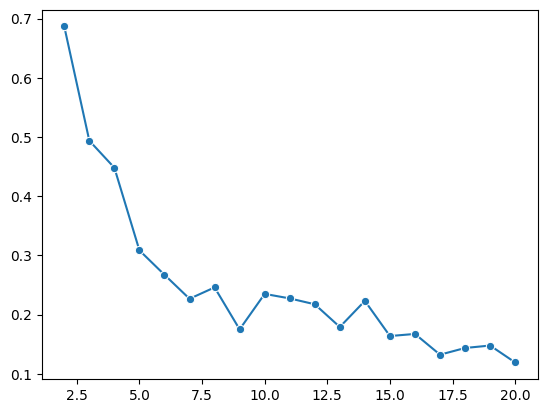

In [26]:
sns.lineplot(x=range(2, 21), y=ss, marker="o")

<Axes: >

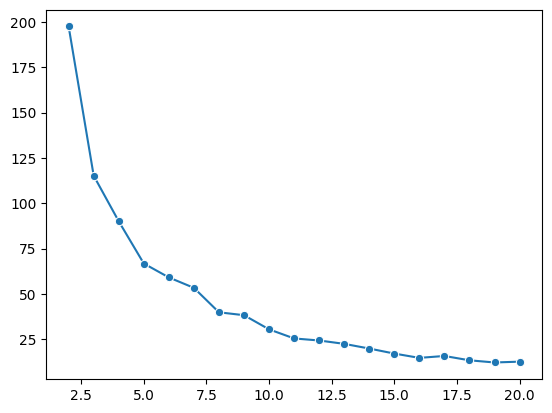

In [28]:
sns.lineplot(x=range(2, 21), y=wcss, marker="o",)

<Axes: >

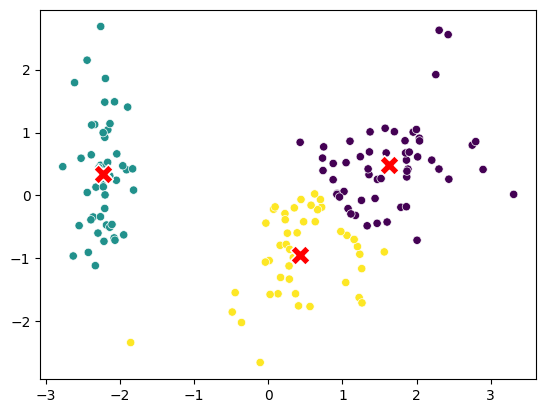

In [43]:
kmeans = KMeans(n_clusters=3, random_state=10)
labels = kmeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], marker="X", c="red", s=200)